In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/pokemons_analysis.csv")

variables_acp = [
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse"
]

X = df[variables_acp]

print("Dimensions :", X.shape)
print("\nValeurs manquantes :")
print(X.isna().sum())

X.describe()

Dimensions : (1100, 6)

Valeurs manquantes :
PV                 0
Attaque            0
Defense            0
AttaqueSpeciale    0
DefenseSpeciale    0
Vitesse            0
dtype: int64


,PV,Attaque,Defense,AttaqueSpeciale,DefenseSpeciale,Vitesse
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,70.785455,81.425455,75.240000,73.409091,72.568182,69.132727
std,26.807156,32.423479,31.148455,32.831911,27.874767,30.132353
min,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000
25%,52.000000,57.750000,52.000000,50.000000,50.000000,45.000000
50%,69.000000,80.000000,70.000000,65.000000,70.000000,66.000000
75%,85.000000,100.000000,92.500000,95.000000,90.000000,90.000000
max,255.000000,190.000000,250.000000,194.000000,250.000000,200.000000


## 1. Standardisation des variables

L'ACP est réalisée sur les six statistiques de combat :
PV, Attaque, Défense, Attaque Spéciale, Défense Spéciale et Vitesse.

La variable `Total` n'est pas utilisée comme variable active puisqu'elle correspond
exactement à la somme de ces six statistiques.

Les variables sont centrées et réduites avant l'ACP afin qu'aucune statistique ne
prenne davantage de poids uniquement en raison de sa dispersion.

In [2]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_acp,
    index=df.index
)

print("Moyennes après standardisation :")
print(X_scaled.mean().round(6))

print("\nÉcarts-types après standardisation :")
print(X_scaled.std(ddof=0).round(6))

Moyennes après standardisation :
PV                 0.0
Attaque            0.0
Defense            0.0
AttaqueSpeciale    0.0
DefenseSpeciale    0.0
Vitesse            0.0
dtype: float64

Écarts-types après standardisation :
PV                 1.0
Attaque            1.0
Defense            1.0
AttaqueSpeciale    1.0
DefenseSpeciale    1.0
Vitesse            1.0
dtype: float64


## 2. Variance expliquée par les composantes principales

L'ACP est appliquée aux six variables centrées-réduites.

Chaque composante principale correspond à une combinaison des statistiques initiales.
On étudie d'abord la part de variance expliquée par chaque axe afin de déterminer
combien de dimensions sont nécessaires pour résumer correctement les profils de combat.

In [3]:
pca = PCA()

coordonnees = pca.fit_transform(X_scaled)

variance_expliquee = pca.explained_variance_ratio_ * 100
variance_cumulee = np.cumsum(variance_expliquee)
valeurs_propres = pca.explained_variance_

resultats_acp = pd.DataFrame({
    "Axe": [f"Dim{i+1}" for i in range(len(variables_acp))],
    "Valeur_propre": valeurs_propres,
    "Variance_expliquee_%": variance_expliquee,
    "Variance_cumulee_%": variance_cumulee
})

resultats_acp.round(2)

,Axe,Valeur_propre,Variance_expliquee_%,Variance_cumulee_%
0,Dim1,2.71,45.15,45.15
1,Dim2,1.11,18.52,63.67
2,Dim3,0.81,13.54,77.21
3,Dim4,0.67,11.20,88.41
4,Dim5,0.43,7.23,95.64
5,Dim6,0.26,4.36,100.00


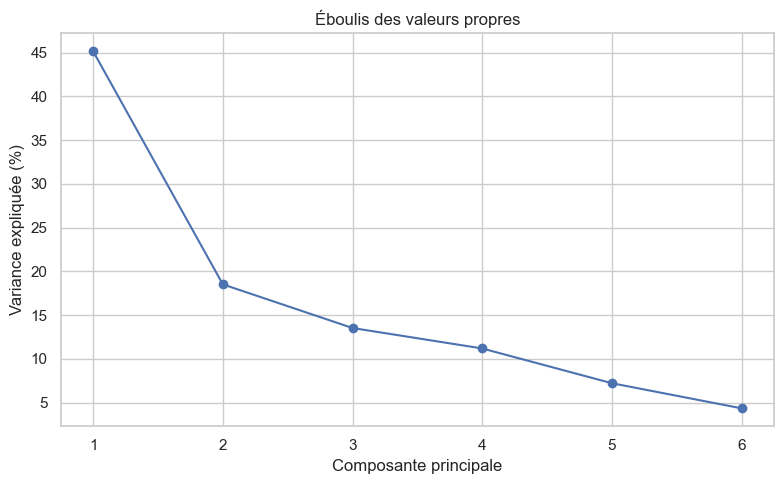

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(variance_expliquee) + 1),
    variance_expliquee,
    marker="o"
)

plt.xlabel("Composante principale")
plt.ylabel("Variance expliquée (%)")
plt.title("Éboulis des valeurs propres")
plt.xticks(range(1, 7))

plt.tight_layout()
plt.show()

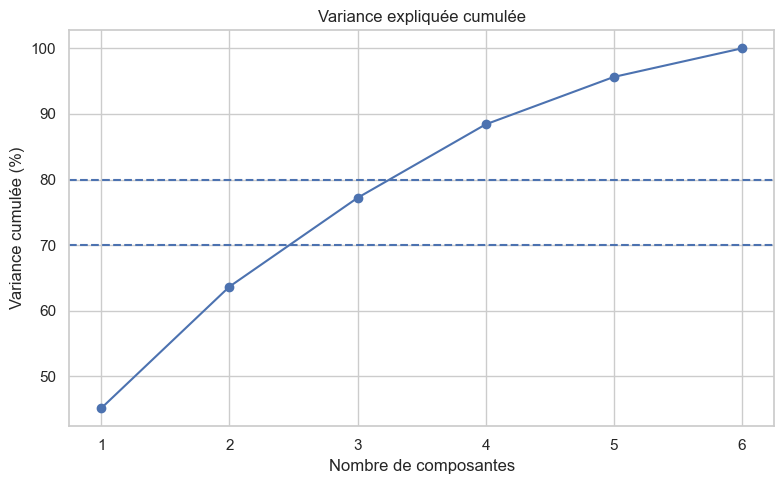

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(variance_cumulee) + 1),
    variance_cumulee,
    marker="o"
)

plt.axhline(70, linestyle="--")
plt.axhline(80, linestyle="--")

plt.xlabel("Nombre de composantes")
plt.ylabel("Variance cumulée (%)")
plt.title("Variance expliquée cumulée")
plt.xticks(range(1, 7))

plt.tight_layout()
plt.show()

### Choix du nombre d'axes

La première composante principale explique 45,15 % de la variance totale et la seconde
18,52 %. Le premier plan factoriel résume ainsi 63,67 % de l'information contenue dans
les six statistiques de combat.

Selon le critère de Kaiser, seules les deux premières composantes présentent une valeur
propre supérieure à 1. Elles sont donc retenues pour l'interprétation graphique
principale.

La troisième composante explique encore 13,54 % de la variance, portant la variance
cumulée à 77,21 %. Elle pourra être conservée pour certaines analyses ultérieures,
notamment la classification.

In [6]:
correlations_variables = (
    pca.components_.T
    * np.sqrt(pca.explained_variance_)
)

correlations_variables = pd.DataFrame(
    correlations_variables,
    index=variables_acp,
    columns=[f"Dim{i+1}" for i in range(len(variables_acp))]
)

correlations_variables.round(3)

,Dim1,Dim2,Dim3,Dim4,Dim5,Dim6
PV,0.679,-0.122,0.262,0.642,-0.183,0.105
Attaque,0.723,0.010,0.581,-0.190,0.199,-0.254
Defense,0.642,-0.607,0.020,-0.374,-0.021,0.284
AttaqueSpeciale,0.719,0.349,-0.361,0.126,0.451,0.111
DefenseSpeciale,0.744,-0.212,-0.520,-0.026,-0.229,-0.281
Vitesse,0.496,0.750,0.072,-0.261,-0.324,0.119


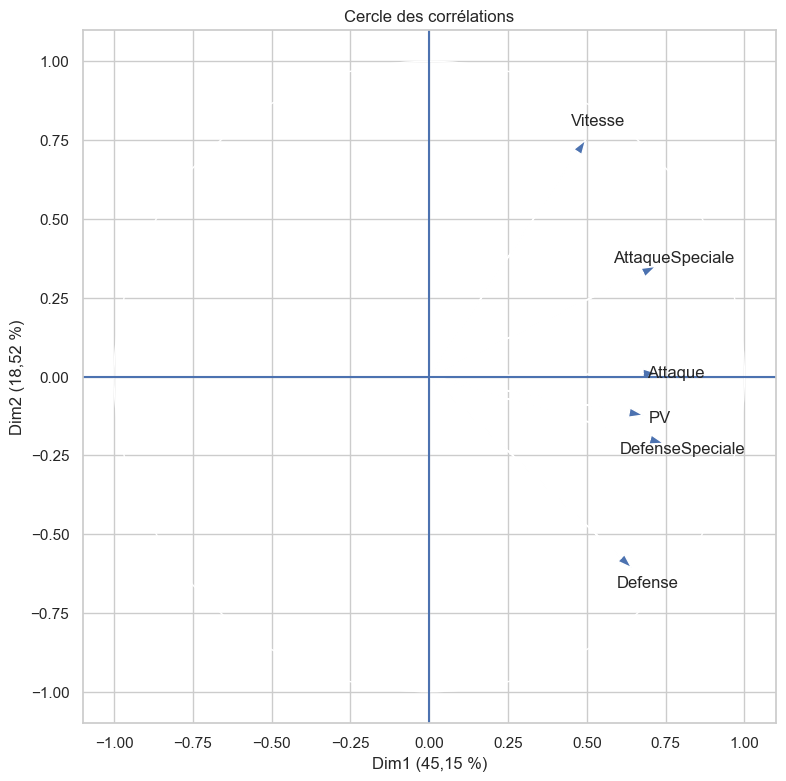

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))

cercle = plt.Circle(
    (0, 0),
    1,
    fill=False
)

ax.add_patch(cercle)

for variable in variables_acp:
    x = correlations_variables.loc[variable, "Dim1"]
    y = correlations_variables.loc[variable, "Dim2"]

    ax.arrow(
        0,
        0,
        x,
        y,
        head_width=0.03,
        length_includes_head=True
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        variable,
        ha="center",
        va="center"
    )

ax.axhline(0)
ax.axvline(0)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)

ax.set_xlabel("Dim1 (45,15 %)")
ax.set_ylabel("Dim2 (18,52 %)")
ax.set_title("Cercle des corrélations")

ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## 3. Interprétation des axes factoriels

Le premier axe, qui explique 45,15 % de la variance, est positivement corrélé à
l'ensemble des statistiques de combat.

Il représente donc principalement un axe de **puissance générale** : les Pokémon situés
du côté positif de Dim1 présentent globalement des statistiques plus élevées.

Le second axe, qui explique 18,52 % de la variance, oppose principalement la Vitesse
(`r = 0,750`) et dans une moindre mesure l'Attaque Spéciale (`r = 0,349`) à la Défense
(`r = -0,607`).

Dim2 peut ainsi être interprété comme un axe opposant des profils plutôt rapides et
orientés vers l'offensive spéciale à des profils plus défensifs et résistants.

Le plan factoriel Dim1-Dim2 résume 63,67 % de la variance totale et fournit donc une
représentation synthétique pertinente des profils de combat.

In [8]:
contributions_variables = (
    correlations_variables**2
    / valeurs_propres
    * 100
)

contributions_variables.round(2)

,Dim1,Dim2,Dim3,Dim4,Dim5,Dim6
PV,16.98,1.35,8.47,61.24,7.72,4.24
Attaque,19.30,0.01,41.47,5.35,9.15,24.73
Defense,15.18,33.08,0.05,20.78,0.10,30.82
AttaqueSpeciale,19.06,10.97,16.06,2.37,46.81,4.73
DefenseSpeciale,20.41,4.05,33.31,0.10,12.06,30.07
Vitesse,9.07,50.55,0.65,10.16,24.16,5.41


### Contributions des variables

Les contributions confirment l'interprétation des deux premiers axes.

Sur Dim1, les contributions sont relativement équilibrées entre les différentes
statistiques, notamment la Défense Spéciale (20,41 %), l'Attaque (19,30 %),
l'Attaque Spéciale (19,06 %), les PV (16,98 %) et la Défense (15,18 %).

Dim1 correspond donc bien à une dimension générale de puissance.

Dim2 est principalement construit par la Vitesse (50,55 %) et la Défense (33,08 %).
Cet axe traduit donc surtout une opposition entre des profils rapides et des profils
défensifs. L'Attaque Spéciale contribue également, mais de manière plus modérée
(10,97 %).

In [9]:
coordonnees_df = pd.DataFrame(
    coordonnees,
    columns=[f"Dim{i+1}" for i in range(len(variables_acp))],
    index=df.index
)

coordonnees_df["Nom"] = df["Nom"]
coordonnees_df["Type1"] = df["Type1"]
coordonnees_df["Legendaire"] = df["Legendaire"]

coordonnees_df.head()

,Dim1,Dim2,Dim3,Dim4,Dim5,Dim6,Nom,Type1,Legendaire
0,-1.640392,-0.012776,-0.747955,0.087194,0.303851,-0.261632,Bulbizarre,Plante,False
1,-0.465529,0.064550,-0.770618,0.121838,0.136577,-0.176180,Herbizarre,Plante,False
2,1.153788,0.143786,-0.746904,0.129482,-0.062895,-0.079386,Florizarre,Plante,False
3,1.153788,0.143786,-0.746904,0.129482,-0.062895,-0.079386,Florizarre Gigamax,Plante,False
4,2.515307,-0.512271,-1.043790,-0.504434,0.274486,0.109818,Méga-Florizarre,Plante,False


In [10]:
print("Extrêmes Dim1 positif")
display(
    coordonnees_df
    .nlargest(10, "Dim1")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

print("Extrêmes Dim1 négatif")
display(
    coordonnees_df
    .nsmallest(10, "Dim1")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

print("Extrêmes Dim2 positif")
display(
    coordonnees_df
    .nlargest(10, "Dim2")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

print("Extrêmes Dim2 négatif")
display(
    coordonnees_df
    .nsmallest(10, "Dim2")
    [["Nom", "Type1", "Legendaire", "Dim1", "Dim2"]]
)

Extrêmes Dim1 positif


,Nom,Type1,Legendaire,Dim1,Dim2
1078,Éthernatos Infinimax,Poison,True,9.647261,-3.340150
484,Primo-Kyogre,Eau,True,4.607750,0.557724
488,Méga-Rayquaza,Dragon,True,4.493636,1.383252
215,Méga-Mewtwo Y,Psy,True,4.487398,2.511552
214,Méga-Mewtwo X,Psy,True,4.448674,1.473433
486,Primo-Groudon,Sol,True,4.356444,-0.524189
966,Ultra-Necrozma,Psy,True,4.075241,1.690520
873,Zygarde - Forme Parfaite,Dragon,True,3.814340,-1.078969
616,Arceus,Normal,True,3.737445,0.299613
1076,Zamazenta - Bouclier Suprême,Combat,True,3.708414,-0.433407


Extrêmes Dim1 négatif


,Nom,Type1,Legendaire,Dim1,Dim2
909,Froussardine - Forme Solitaire,Eau,False,-3.627059,0.281602
995,Larvadar,Insecte,False,-3.560416,0.341896
258,Tournegrin,Plante,False,-3.549481,-0.056947
182,Magicarpe,Eau,False,-3.523230,0.619906
1054,Frissonille,Glace,False,-3.455127,-0.235393
20,Aspicot,Insecte,False,-3.423079,0.344530
16,Chenipan,Insecte,False,-3.401369,0.111042
440,Barpau,Eau,False,-3.392540,0.964722
362,Tarsal,Psy,False,-3.329993,0.394013
381,Azurill,Normal,False,-3.323150,-0.740383


Extrêmes Dim2 positif


,Nom,Type1,Legendaire,Dim1,Dim2
491,Deoxys - Forme Attaque,Psy,True,1.699395,4.503097
1085,Regieleki,Électrik,True,1.374003,3.952193
958,Cancrelove,Insecte,False,1.365890,3.552587
490,Deoxys - Forme Normale,Psy,True,1.755512,3.420922
92,Méga-Alakazam,Psy,False,1.726828,3.020962
751,Limaspeed,Insecte,False,0.454391,2.757804
374,Ninjask,Insecte,False,-0.181464,2.675088
493,Deoxys - Forme Vitesse,Psy,True,1.727441,2.530483
215,Méga-Mewtwo Y,Psy,True,4.487398,2.511552
801,Amphinobi - Forme Sacha,Eau,False,2.439275,2.463909


Extrêmes Dim2 négatif


,Nom,Type1,Legendaire,Dim1,Dim2
285,Caratroc,Insecte,False,1.255238,-5.949744
971,Ama-Ama,Roche,False,1.848715,-4.187513
278,Méga-Steelix,Acier,False,2.319815,-4.136065
392,Méga-Galeking,Acier,False,2.469531,-3.479224
277,Steelix,Acier,False,0.915774,-3.376783
1078,Éthernatos Infinimax,Poison,True,9.647261,-3.340150
518,Bastiodon,Roche,False,0.914407,-3.337914
935,Concombaffe,Eau,False,-0.135464,-3.315987
476,Regirock,Roche,True,1.896927,-3.225181
865,Séracrawl,Glace,False,0.982521,-3.179774


## 4. Interprétation des individus

L'étude des individus extrêmes confirme l'interprétation des deux premiers axes.

Les Pokémon les plus positifs sur Dim1 sont principalement des formes très puissantes,
souvent légendaires, comme Éthernatos Infinimax, Primo-Kyogre, Méga-Rayquaza ou
Méga-Mewtwo. À l'inverse, les Pokémon situés à l'extrémité négative de Dim1 sont
des formes globalement faibles comme Magicarpe, Chenipan ou Froussardine - Forme Solitaire.

Dim1 représente donc bien un axe de puissance générale.

Sur Dim2, les valeurs positives sont associées à des Pokémon très rapides et souvent
orientés vers l'offensive spéciale, comme Deoxys - Forme Attaque, Regieleki ou
Méga-Alakazam.

À l'opposé, les valeurs fortement négatives correspondent à des Pokémon très défensifs
et généralement lents, comme Caratroc, Ama-Ama ou Méga-Steelix.

L'exemple de Caratroc est particulièrement cohérent avec l'analyse exploratoire :
il apparaît comme l'individu le plus extrême du côté défensif de Dim2.

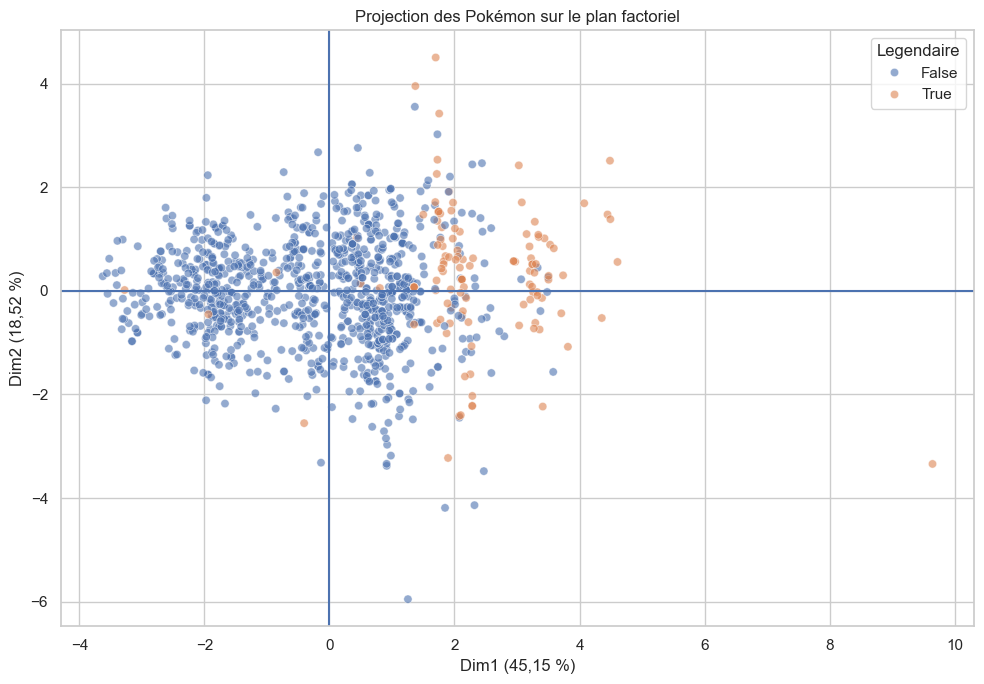

In [11]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=coordonnees_df,
    x="Dim1",
    y="Dim2",
    hue="Legendaire",
    alpha=0.6
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("Dim1 (45,15 %)")
plt.ylabel("Dim2 (18,52 %)")
plt.title("Projection des Pokémon sur le plan factoriel")

plt.tight_layout()
plt.show()

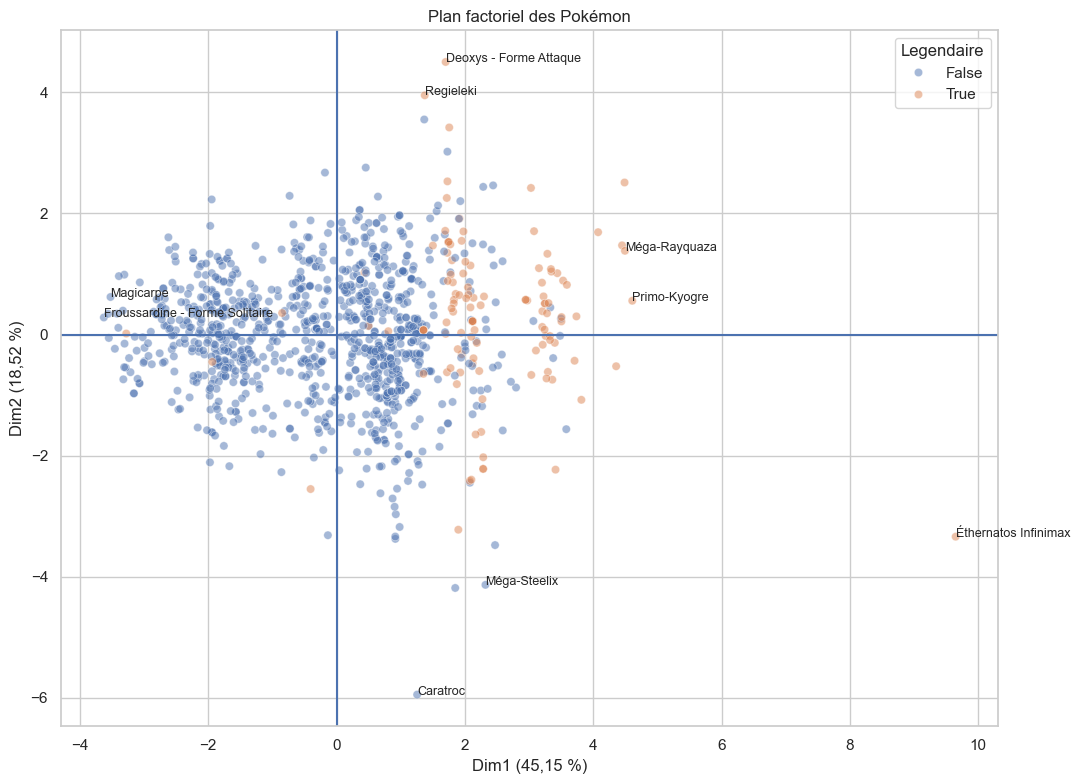

In [12]:
noms_a_afficher = [
    "Éthernatos Infinimax",
    "Primo-Kyogre",
    "Méga-Rayquaza",
    "Magicarpe",
    "Froussardine - Forme Solitaire",
    "Deoxys - Forme Attaque",
    "Regieleki",
    "Caratroc",
    "Méga-Steelix"
]

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=coordonnees_df,
    x="Dim1",
    y="Dim2",
    hue="Legendaire",
    alpha=0.5
)

for nom in noms_a_afficher:
    ligne = coordonnees_df[coordonnees_df["Nom"] == nom]

    if not ligne.empty:
        x = ligne["Dim1"].iloc[0]
        y = ligne["Dim2"].iloc[0]

        plt.text(
            x,
            y,
            nom,
            fontsize=9
        )

plt.axhline(0)
plt.axvline(0)

plt.xlabel("Dim1 (45,15 %)")
plt.ylabel("Dim2 (18,52 %)")
plt.title("Plan factoriel des Pokémon")

plt.tight_layout()
plt.show()

### Projection des individus

La projection des Pokémon sur le plan factoriel confirme les interprétations précédentes.

Les Pokémon légendaires sont majoritairement situés du côté positif de Dim1, ce qui
traduit leur niveau global de statistiques généralement plus élevé. Un recouvrement
subsiste toutefois avec les Pokémon non légendaires, ce qui montre que le statut
légendaire ne détermine pas à lui seul la position sur le plan factoriel.

Les individus extrêmes sur Dim2 illustrent également clairement l'opposition entre
profils rapides et profils défensifs. Deoxys - Forme Attaque et Regieleki se situent
parmi les valeurs les plus positives de l'axe, tandis que Caratroc et Méga-Steelix
occupent les valeurs les plus négatives.

Éthernatos Infinimax constitue un individu particulièrement atypique, avec une position
extrême sur Dim1 en raison de ses statistiques globalement très élevées.

In [15]:
from scipy import stats

rho_dim1_total, p_dim1_total = stats.spearmanr(
    coordonnees_df["Dim1"],
    df["Total"]
)

print("Corrélation Dim1 / Total :", rho_dim1_total)
print("p-value :", p_dim1_total)

Corrélation Dim1 / Total : 0.9952144550708982
p-value : 0.0


### Validation de l'interprétation de Dim1

La corrélation de Spearman entre la coordonnée des individus sur Dim1 et leur `Total`
est extrêmement élevée (`rho = 0,995`, `p < 0,001`).

Ce résultat confirme quantitativement que la première composante principale représente
essentiellement un axe de puissance globale des Pokémon.

L'ACP apporte néanmoins une information supplémentaire au simple `Total`, notamment
grâce à Dim2, qui distingue les profils rapides des profils davantage orientés vers
la défense.